# MarketLens: Product Predictor (Random Forest)

**Owner:** Vishal Baskar  ·  **Dataset:** [Amazon Products Dataset 2023 (1.4M products), Kaggle](https://www.kaggle.com/datasets/asaniczka/amazon-products-dataset-2023-1-4m-products)

**Goal:** predict whether a product will be a **top-20% seller in its own category**. This is the team's shared target, so my Random Forest can be compared with my teammates' models using the same metrics (ROC-AUC and PR-AUC). It answers a seller's real question: *once I've picked a niche, which products win inside it?*

### Where this stands
- **Version 2 (main model, Oct 14, 2026):** predicts the shared target. It's tested on my teammate's exact train/test split, and his title-score and brand features are added, so both models get the same products and the same inputs. Results print in section 14 after you run the notebook.
- **Before adding his title features** (same split): my Random Forest scored ROC-AUC 0.81 / PR-AUC 0.49 (full) and 0.75 / 0.40 (launch-time), vs. his XGBoost's 0.85 / 0.58 and 0.81 / 0.50.
- **Version 1 (appendix):** predicted monthly sales across all products. Random Forest R² 0.55, vs. 0.46 for guessing the category average.
- **Why the switch (teammate feedback):**
  1. Version 1's target was different from his, so R² vs. his ROC-AUC wasn't a fair comparison.
  2. Most of the R² came from knowing the category.
  3. `isBestSeller` leaks the answer, because Amazon sets it from sales.

  Version 2 fixes all three.

### How to use this notebook
- Each grey box is a **code cell**. Click inside it and press **Shift + Enter** to run it and move to the next one.
- Run cells **from top to bottom, in order**. Later cells use results from earlier ones.
- White boxes like this one are **notes**. They explain what the next cell does and why.
- If something breaks or you lose track: click **Restart** in the top toolbar, then **Run All**.

### Sections
1. Setup · 2. Load the data · 3. First look · 4. Cleaning · 5. Outliers · 6. Sales across categories
7. Features · 8. The target · 9. Train/test split · 10. Title score & brand (teammate's features)
11. Scoring & baselines · 12. Random Forest · 13. Results · 14. Meeting summary & saved results
Appendix: my first approach (sales, R²)

## 1. Setup

These are the libraries (pre-written code toolkits) we use:

| Library | What it does for us |
|---|---|
| **pandas** | Works with tables (called *DataFrames*), like Excel in code: load, filter, group, summarize |
| **numpy** | Fast math on whole columns at once (logs, averages, etc.) |
| **matplotlib** | Draws the charts |
| **scikit-learn** (`sklearn`) | The machine-learning toolkit: splitting data, the Random Forest, scoring |

The **Settings** block is the only part you might want to change:
- `MODEL_SAMPLE_SIZE` controls how many products we train on. 300,000 trains in a few minutes on a normal laptop. `None` uses everything, which is slower.
- `TOP_SHARE`, `SPLIT_FILE`, `USE_TITLE_FEATURES` and `TEAMMATE_SCORES` control the comparison with my teammate (sections 8, 9, 10 and 13).
- `MIN_SAMPLES_LEAF` sets the smallest group a Random Forest leaf can hold. 50 keeps training on about 1M products manageable on a laptop.
- `RUN_APPENDIX` re-runs my first (sales) model at the end. It's off by default because it trains two more big models.

In [1]:
# ---------- Libraries ----------
import json
import re
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split, KFold, StratifiedKFold
from sklearn.feature_extraction.text import HashingVectorizer, TfidfTransformer
from sklearn.linear_model import SGDClassifier
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             mean_absolute_error, mean_squared_error, r2_score)

# ---------- Settings you can change ----------
DATA_DIR = Path("data")            # folder holding amazon_products.csv and amazon_categories.csv
RESULTS_DIR = Path("results")      # where charts and result tables get saved
RANDOM_STATE = 42                  # fixes the randomness so you get the same results every run
MODEL_SAMPLE_SIZE = 300_000        # products used for training/testing (None = all of them, slower)
MIN_PRODUCTS_PER_CATEGORY = 500    # some category charts skip tiny categories (too few products to trust)

# ---------- Team comparison settings ----------
TOP_SHARE = 0.20                                  # target = top 20% of its own category
SPLIT_FILE = DATA_DIR / "split_for_vishal.csv"    # teammate's exact train/test split (asin, split); used if the file exists
USE_TITLE_FEATURES = True                         # add teammate's title_score + brand_rate (section 10)
MIN_SAMPLES_LEAF = 50                             # Random Forest leaf size (bigger = smaller, faster trees)
RUN_APPENDIX = False                              # True = also re-run my first (sales) model at the end
TEAMMATE_SCORES = {                               # teammate's XGBoost: same split, same target
    "full":        {"ROC-AUC": 0.85, "PR-AUC": 0.58, "ROC-AUC within category": 0.81},
    "launch-time": {"ROC-AUC": 0.81, "PR-AUC": 0.50, "ROC-AUC within category": 0.76},
}

# ---------- Display settings (just makes things look nicer) ----------
RESULTS_DIR.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
BLUE, ORANGE, GRAY, AQUA = "#2a78d6", "#eb6834", "#9a9893", "#1baf7a"
plt.rcParams.update({
    "figure.figsize": (10, 5), "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
})

print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

pandas 3.0.6 | scikit-learn 1.9.1


## 2. Load the data

The dataset comes as **two CSV files**:
- `amazon_products.csv`: one row per product (about 1.4 million rows)
- `amazon_categories.csv`: a lookup table that turns `category_id` numbers into names like "Toys & Games"

We skip the image and URL columns because they don't help predict sales and they take up a lot of memory. Loading takes around 30–60 seconds.

In [2]:
products_path = DATA_DIR / "amazon_products.csv"
categories_path = DATA_DIR / "amazon_categories.csv"

# Friendly error if the files aren't where we expect
for p in [products_path, categories_path]:
    if not p.exists():
        raise FileNotFoundError(
            f"Can't find {p.resolve()}\n"
            "Download the dataset from Kaggle, unzip it, and put BOTH csv files in a folder named 'data' "
            "next to this notebook (see the setup guide)."
        )

# Check the columns are the ones we expect before loading 1.4M rows
COLUMNS_WE_USE = ["asin", "title", "stars", "reviews", "price", "listPrice",
                  "category_id", "isBestSeller", "boughtInLastMonth"]
columns_in_file = pd.read_csv(products_path, nrows=0).columns.tolist()
missing = [c for c in COLUMNS_WE_USE if c not in columns_in_file]
if missing:
    raise ValueError(f"These columns are missing: {missing}\nColumns found in the file: {columns_in_file}")

start = time.time()
products = pd.read_csv(products_path, usecols=COLUMNS_WE_USE)
categories = pd.read_csv(categories_path)
print(f"Loaded in {time.time() - start:.0f} seconds")
print(f"Products table:   {products.shape[0]:,} rows x {products.shape[1]} columns")
print(f"Categories table: {categories.shape[0]:,} rows x {categories.shape[1]} columns")

Loaded in 2 seconds
Products table:   1,426,337 rows x 9 columns
Categories table: 248 rows x 2 columns


Next we attach the category **name** to every product. This is a **merge**, the pandas version of Excel's VLOOKUP: match `products.category_id` to `categories.id`.

In [3]:
df = products.merge(
    categories.rename(columns={"id": "category_id"}),
    on="category_id",
    how="left",            # keep every product, even if its category id has no name
)
df.head()

,asin,title,stars,reviews,price,listPrice,category_id,isBestSeller,boughtInLastMonth,category_name
0,B014TMV5YE,"Sion Softside Expandable Roller Luggage, Black...",4.50,0,139.99,0.00,104,False,2000,Suitcases
1,B07GDLCQXV,Luggage Sets Expandable PC+ABS Durable Suitcas...,4.50,0,169.99,209.99,104,False,1000,Suitcases
2,B07XSCCZYG,Platinum Elite Softside Expandable Checked Lug...,4.60,0,365.49,429.99,104,False,300,Suitcases
3,B08MVFKGJM,Freeform Hardside Expandable with Double Spinn...,4.60,0,291.59,354.37,104,False,400,Suitcases
4,B01DJLKZBA,Winfield 2 Hardside Expandable Luggage with Sp...,4.50,0,174.99,309.99,104,False,400,Suitcases


## 3. First look

Before changing anything, we check what we're working with:
- **`info()`**: each column's data type (number, text, true/false) and how many values are filled in
- **`describe()`**: quick stats (average, min, max, quartiles) for every number column
- **Missing values and zeros**: these are usually where data problems hide

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1426337 entries, 0 to 1426336
Data columns (total 10 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   asin               1426337 non-null  str    
 1   title              1426336 non-null  str    
 2   stars              1426337 non-null  float64
 3   reviews            1426337 non-null  int64  
 4   price              1426337 non-null  float64
 5   listPrice          1426337 non-null  float64
 6   category_id        1426337 non-null  int64  
 7   isBestSeller       1426337 non-null  bool   
 8   boughtInLastMonth  1426337 non-null  int64  
 9   category_name      1426337 non-null  str    
dtypes: bool(1), float64(3), int64(3), str(3)
memory usage: 307.1 MB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
stars,"1,426,337.00",4.00,1.34,0.00,4.10,4.40,4.60,5.00
reviews,"1,426,337.00",180.75,"1,761.45",0.00,0.00,0.00,0.00,"346,563.00"
price,"1,426,337.00",43.38,130.29,0.00,11.99,19.95,35.99,"19,731.81"
listPrice,"1,426,337.00",12.45,46.11,0.00,0.00,0.00,0.00,999.99
category_id,"1,426,337.00",123.74,73.11,1.00,65.00,120.00,176.00,270.00
boughtInLastMonth,"1,426,337.00",141.98,836.27,0.00,0.00,0.00,50.00,"100,000.00"


In [6]:
number_cols = df.select_dtypes("number").columns
health = pd.DataFrame({
    "missing": df.isna().sum(),
    "zeros": (df[number_cols] == 0).sum().reindex(df.columns).astype("Int64"),   # only for number columns
})
health["missing_%"] = health["missing"] / len(df) * 100
health["zeros_%"] = health["zeros"] / len(df) * 100
health

,missing,zeros,missing_%,zeros_%
asin,0,<NA>,0.00,<NA>
title,1,<NA>,0.00,<NA>
stars,0,131023,0.00,9.19
reviews,0,1130503,0.00,79.26
price,0,32772,0.00,2.30
listPrice,0,1080503,0.00,75.75
category_id,0,0,0.00,0.00
isBestSeller,0,<NA>,0.00,<NA>
boughtInLastMonth,0,917620,0.00,64.33
category_name,0,<NA>,0.00,<NA>


### What do the sales numbers look like?

Our target is built from `boughtInLastMonth`, so its quirks matter. It comes from Amazon's **"50+ bought in past month"** badge. So it is **not an exact sales number**. It's rounded into buckets (50, 100, 200, ... 1,000, 2,000, ...). A **0 usually means Amazon didn't show a badge**, which can mean low sales, not necessarily zero sales. This is a limitation worth mentioning in the meeting.

In [7]:
target_counts = df["boughtInLastMonth"].value_counts().sort_index()
print("Distinct values:", target_counts.index.astype(int).tolist())
print(f"\nProducts with 0 (no sales badge): {(df['boughtInLastMonth'] == 0).mean():.1%}")
print(f"Products marked Best Seller:      {df['isBestSeller'].astype(str).str.lower().eq('true').mean():.2%}")
target_counts.to_frame("number_of_products").head(15)

Distinct values: [0, 50, 100, 200, 300, 400, 500, 600, 700, 800, 900, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, 10000, 20000, 30000, 40000, 50000, 60000, 70000, 80000, 90000, 100000]

Products with 0 (no sales badge): 64.3%
Products marked Best Seller:      0.60%


,number_of_products
boughtInLastMonth,
0,917620
50,157252
100,132404
200,62460
300,36196
400,22887
500,15996
600,11983
700,9133


## 4. Cleaning

**Data cleaning** means fixing or removing rows that are wrong, duplicated, or unusable, so the model doesn't learn from bad information. We keep a **cleaning log** so we can show exactly what changed and why.

| Rule | Why |
|---|---|
| Remove duplicate `asin` (Amazon's product ID) | The same product counted twice would get double weight |
| Remove `price` ≤ 0 or missing | A product can't really cost $0; these are scraping errors or unavailable items |
| Remove missing `boughtInLastMonth` | We can't learn from a row with no answer |
| `listPrice` = 0 → set equal to `price` | 0 means Amazon showed no "was" price, so there is **no discount** |
| `stars` = 0 with 0 reviews → add a `has_reviews` flag | It means **"not rated yet"**, not a 0-star product. The flag lets the model tell the difference |
| Missing title / category → blank / "Unknown" | Keeps the row instead of throwing it away |

In [8]:
cleaning_log = []

def log_step(step, rows_before, rows_after):
    cleaning_log.append({"step": step, "rows_before": rows_before,
                         "rows_after": rows_after, "rows_removed": rows_before - rows_after})
    print(f"{step:<40} removed {rows_before - rows_after:>9,}   ->  {rows_after:,} rows left")

clean = df.copy()

# 4.1 Duplicates
n = len(clean)
clean = clean.drop_duplicates(subset="asin")
log_step("Remove duplicate ASINs", n, len(clean))

# 4.2 Impossible prices (this also drops missing prices)
n = len(clean)
clean = clean[clean["price"] > 0]
log_step("Remove price <= 0 or missing", n, len(clean))

# 4.3 Missing target
n = len(clean)
clean = clean.dropna(subset=["boughtInLastMonth"])
log_step("Remove missing boughtInLastMonth", n, len(clean))

# 4.4 Fixes that keep the row
clean["title"] = clean["title"].fillna("")
clean["category_name"] = clean["category_name"].fillna("Unknown")
clean["reviews"] = clean["reviews"].fillna(0)
clean["stars"] = clean["stars"].fillna(0)
clean["isBestSeller"] = clean["isBestSeller"].astype(str).str.lower().isin(["true", "1"]).astype(int)

no_list_price = clean["listPrice"].isna() | (clean["listPrice"] <= 0) | (clean["listPrice"] < clean["price"])
clean.loc[no_list_price, "listPrice"] = clean.loc[no_list_price, "price"]

clean["has_reviews"] = (clean["reviews"] > 0).astype(int)

print(f"\nlistPrice set to price (no discount) on {no_list_price.sum():,} rows")
print(f"Products with no reviews yet: {(clean['has_reviews'] == 0).mean():.1%}")
print(f"\nFinal clean table: {len(clean):,} rows ({len(clean) / len(df):.1%} of the original kept)")

pd.DataFrame(cleaning_log)

Remove duplicate ASINs                   removed         0   ->  1,426,337 rows left
Remove price <= 0 or missing             removed    32,772   ->  1,393,565 rows left
Remove missing boughtInLastMonth         removed         0   ->  1,393,565 rows left

listPrice set to price (no discount) on 1,048,231 rows
Products with no reviews yet: 79.2%

Final clean table: 1,393,565 rows (97.7% of the original kept)


,step,rows_before,rows_after,rows_removed
0,Remove duplicate ASINs,1426337,1426337,0
1,Remove price <= 0 or missing,1426337,1393565,32772
2,Remove missing boughtInLastMonth,1393565,1393565,0


## 5. Outliers

An **outlier** is a value far away from the rest, like a $9,000 product in a dataset where most things cost $20. Some outliers are **errors** (delete them). Others are **real but unusual** (usually keep them).

**The IQR rule** is the standard first check:
- **Q1** = the value 25% of the way up the sorted data; **Q3** = the value 75% of the way up
- **IQR** = Q3 − Q1 (the spread of the "middle half" of products)
- Anything above **Q3 + 1.5 × IQR** or below **Q1 − 1.5 × IQR** gets flagged as an outlier

For star ratings we only look at products that actually have reviews.

In [9]:
def iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return lower, upper, (series < lower) | (series > upper)

rows = []
for col in ["price", "reviews", "stars", "boughtInLastMonth"]:
    s = clean.loc[clean["has_reviews"] == 1, col] if col == "stars" else clean[col]
    lower, upper, is_outlier = iqr_outliers(s)
    rows.append({"column": col, "median": s.median(), "Q3": s.quantile(0.75),
                 "upper_fence": upper, "99th_percentile": s.quantile(0.99), "max": s.max(),
                 "outliers": int(is_outlier.sum()), "outliers_%": is_outlier.mean() * 100})
outlier_table = pd.DataFrame(rows).set_index("column")
outlier_table

,median,Q3,upper_fence,99th_percentile,max,outliers,outliers_%
column,,,,,,,
price,19.99,36.96,74.41,413.46,"19,731.81",156524,11.23
reviews,0.00,0.00,0.00,"3,734.36","346,563.00",290127,20.82
stars,4.50,4.70,5.45,5.00,5.00,10011,3.45
boughtInLastMonth,0.00,50.00,125.00,"2,000.00","100,000.00",216877,15.56


**How to read this:** look at how far `max` is from `median`. That gap shows how **skewed** each column is: lots of small values and a long tail of huge ones.

For `boughtInLastMonth` (and usually `reviews`), most products sit at or near 0. That makes Q1, Q3 and the IQR tiny, so the rule flags **every product that sells at all** as an "outlier". So the IQR rule is the wrong tool for these columns. That's a useful finding in itself.

The charts below show the skew. The top row is the raw data. The bottom row uses a **log scale**, which squishes the long tail so you can see the shape. We use `log(1 + x)` so that 0 stays 0.

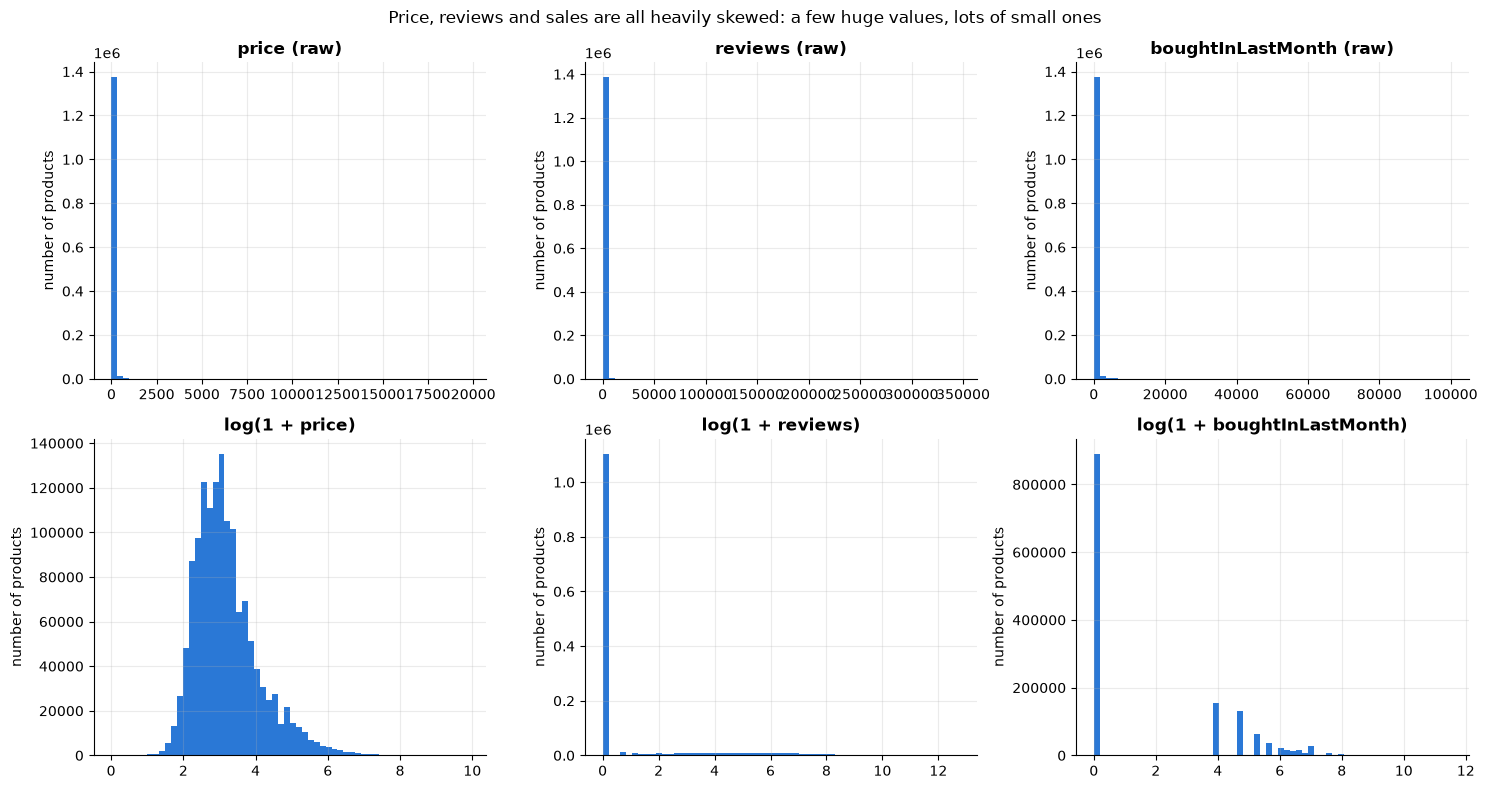

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(["price", "reviews", "boughtInLastMonth"]):
    axes[0, i].hist(clean[col], bins=60, color=BLUE)
    axes[0, i].set_title(f"{col} (raw)")
    axes[1, i].hist(np.log1p(clean[col]), bins=60, color=BLUE)
    axes[1, i].set_title(f"log(1 + {col})")
    axes[0, i].set_ylabel("number of products")
    axes[1, i].set_ylabel("number of products")
plt.suptitle("Price, reviews and sales are all heavily skewed: a few huge values, lots of small ones")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "distributions.png", dpi=120)
plt.show()

### Are the extreme prices real or errors?
Eyeball the most expensive products. If they look like real items (TVs, furniture, equipment), they're real. If a phone case costs $5,000, it's an error.

In [11]:
(clean.nlargest(10, "price")
      .assign(title=lambda d: d["title"].str[:70])
      [["title", "category_name", "price", "reviews", "boughtInLastMonth"]])

,title,category_name,price,reviews,boughtInLastMonth
594853,Overland Storage Neoxl80 Storagelibrary Lto8 SAS,Data Storage,"19,731.81",0,0
108907,replicas Marinas,Fabric Decorating,"19,400.00",0,0
994047,CISCO Systems 1 Port ATM Enhanced Oc12/Stm4 Si...,Computer Servers,"16,468.70",0,0
994048,Cisco Systems 7140 Router Dual 10/100 Fe Dual ...,Computer Servers,"12,629.66",0,0
868945,PARTNERS BRAND Corrugated Trash Can Plain - 40...,Packaging & Shipping Supplies,"12,519.96",0,0
124354,Sony VPL-XW6000ES 4K HDR Laser Home Theater Pr...,Office Electronics,"11,998.00",5,0
594770,HPE MSA 2062 10GBASE-T iSCSI SFF Storage,Data Storage,"11,214.12",0,0
994067,CISCO Systems Catalyst 5000 Family Supervisor ...,Computer Servers,"10,859.09",0,0
594779,Aruba a Hewlett Packard Enterprise company HPE...,Data Storage,"10,118.20",0,0
735132,"A-PS-SS70T-100, Black","PlayStation 3 Games, Consoles & Accessories","10,010.00",0,0


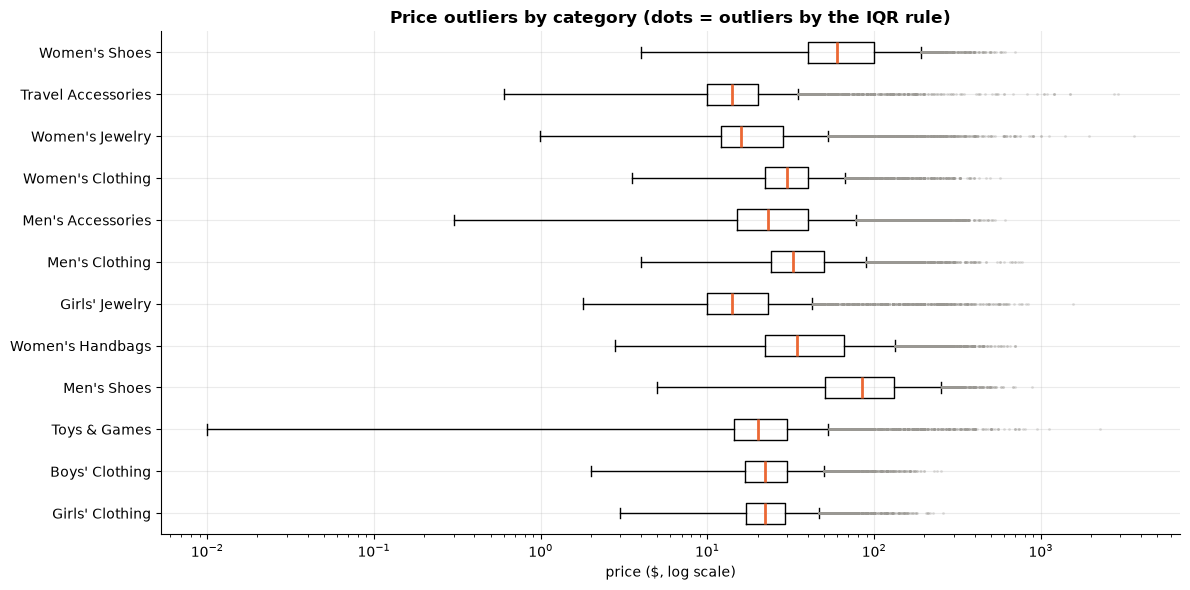

In [12]:
# Price spread inside the 12 biggest categories (log scale, so $1 to $10,000 fits on one chart)
top_cats = clean["category_name"].value_counts().head(12).index
data = [clean.loc[clean["category_name"] == c, "price"] for c in top_cats]

fig, ax = plt.subplots(figsize=(12, 6))
ax.boxplot(data, orientation="horizontal", tick_labels=[c[:35] for c in top_cats], showfliers=True,
           flierprops={"marker": ".", "markersize": 2, "alpha": 0.3, "markeredgecolor": GRAY},
           medianprops={"color": ORANGE, "linewidth": 2})
ax.set_xscale("log")
ax.set_xlabel("price ($, log scale)")
ax.set_title("Price outliers by category (dots = outliers by the IQR rule)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "price_outliers_by_category.png", dpi=120)
plt.show()

### Outlier decision

- **Removed:** values that can't be true (price ≤ 0), already handled in cleaning.
- **Kept:** real-but-extreme products (expensive items, mega-sellers). Deleting them would hide exactly the products sellers care about.
- **Why keeping them is OK for a Random Forest:** a Random Forest makes decisions like "is price above $40?". Only the **order** of values matters, so one $9,000 product can't drag the model the way it would drag an average or a straight-line model.
- **Handling the skewed sales numbers:** the main model predicts a yes/no label ("top 20% of its category"), so a handful of 50,000+ sellers can't dominate it. My first model (appendix) predicted sales directly, so it used **log(1 + sales)** for the same reason.

## 6. How sales are spread across categories

Now the market view, which is exactly what MarketLens is about. For each category we calculate:
- **products**: how many listings, a rough measure of **competition**
- **pct_with_sales**: % of products showing a sales badge (how many listings actually sell)
- **avg_monthly_sales**: average units per product
- **total_monthly_sales**: all badge values added up (a rough, **lower-bound** demand estimate, since the badges are rounded down)
- **share_of_all_sales_%**: the category's slice of the whole pie

`groupby` means "split the table by category, calculate each stat per group, then put the results back together".

In [13]:
cat = (clean.assign(has_sales=clean["boughtInLastMonth"] > 0)
            .groupby("category_name")
            .agg(products=("asin", "size"),
                 pct_with_sales=("has_sales", "mean"),
                 avg_monthly_sales=("boughtInLastMonth", "mean"),
                 total_monthly_sales=("boughtInLastMonth", "sum"),
                 median_price=("price", "median"),
                 pct_bestseller=("isBestSeller", "mean"))
            .sort_values("total_monthly_sales", ascending=False))
cat["pct_with_sales"] *= 100
cat["pct_bestseller"] *= 100
cat["share_of_all_sales_%"] = cat["total_monthly_sales"] / cat["total_monthly_sales"].sum() * 100

top10_share = cat["share_of_all_sales_%"].head(10).sum()
print(f"{len(cat)} categories in total")
print(f"The top 10 categories account for {top10_share:.1f}% of all estimated monthly sales")
cat.head(15)

248 categories in total
The top 10 categories account for 32.2% of all estimated monthly sales


,products,pct_with_sales,avg_monthly_sales,total_monthly_sales,median_price,pct_bestseller,share_of_all_sales_%
category_name,,,,,,,
Kitchen & Dining,4864,99.12,"2,136.33",10391100,16.23,5.74,5.19
Hair Care Products,8548,99.71,927.19,7925600,14.95,0.51,3.96
Industrial & Scientific,4412,87.65,"1,599.69",7057850,14.99,9.07,3.52
Household Cleaning Supplies,8280,85.75,819.26,6783500,15.57,0.63,3.39
Skin Care Products,7801,99.41,820.75,6402700,16.95,0.32,3.20
Health & Household,714,99.58,"8,458.40",6039300,12.78,7.56,3.01
Toys & Games,20657,59.28,278.18,5746350,19.99,1.16,2.87
Home Storage & Organization,15099,59.12,353.58,5338750,23.99,0.78,2.66
Dog Supplies,8248,98.15,550.10,4537250,17.96,1.27,2.26


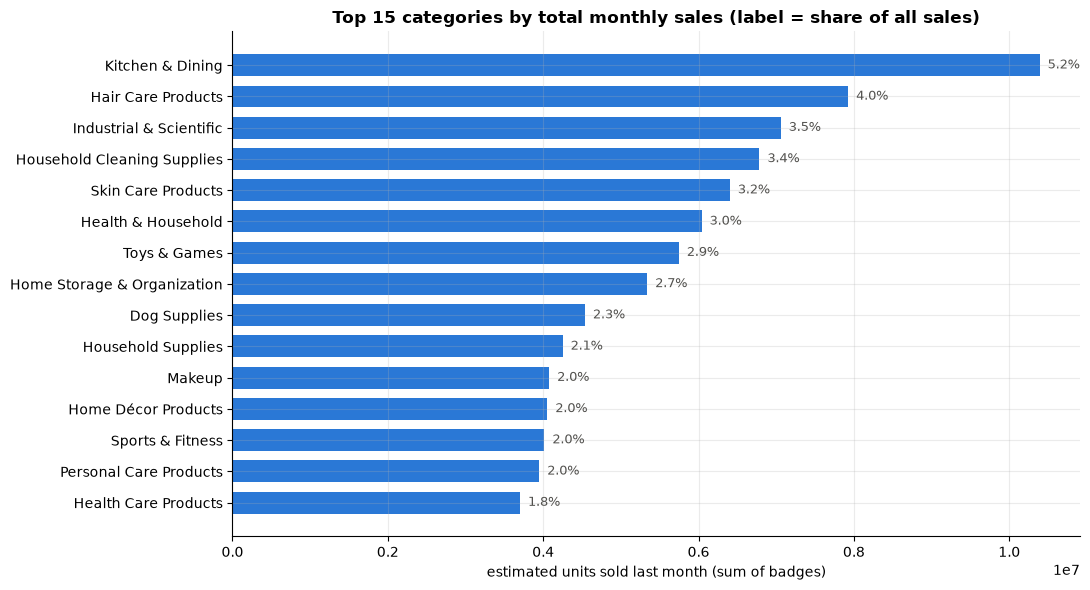

In [14]:
top15 = cat.head(15).iloc[::-1]          # reversed so the biggest bar is on top
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(top15.index.str[:40], top15["total_monthly_sales"], color=BLUE, height=0.7)
for y, (v, s) in enumerate(zip(top15["total_monthly_sales"], top15["share_of_all_sales_%"])):
    ax.text(v, y, f"  {s:.1f}%", va="center", fontsize=9, color="#52514e")
ax.set_xlabel("estimated units sold last month (sum of badges)")
ax.set_title("Top 15 categories by total monthly sales (label = share of all sales)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "top_categories_by_sales.png", dpi=120)
plt.show()

**Total sales favors big categories just because they have more products.** So the next chart asks a fairer question: *in which categories does a typical listing actually sell?* We only include categories with at least `MIN_PRODUCTS_PER_CATEGORY` products so small categories don't give fluke results.

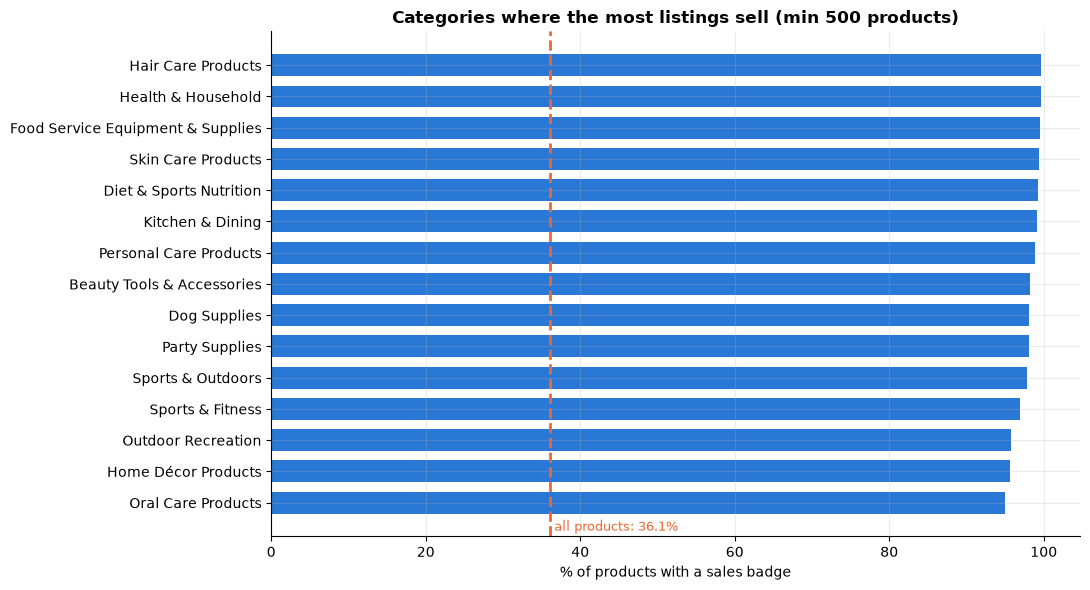

In [15]:
big = cat[cat["products"] >= MIN_PRODUCTS_PER_CATEGORY]
best = big.sort_values("pct_with_sales", ascending=False).head(15).iloc[::-1]
overall = (clean["boughtInLastMonth"] > 0).mean() * 100

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(best.index.str[:40], best["pct_with_sales"], color=BLUE, height=0.7)
ax.axvline(overall, color=ORANGE, linestyle="--", linewidth=2)
ax.text(overall, -0.9, f" all products: {overall:.1f}%", color=ORANGE, fontsize=9)
ax.set_xlabel("% of products with a sales badge")
ax.set_title(f"Categories where the most listings sell (min {MIN_PRODUCTS_PER_CATEGORY:,} products)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "categories_pct_selling.png", dpi=120)
plt.show()

### Opportunity map: demand vs. competition
This chart is where MarketLens's "opportunity score" idea starts. Each dot is a category:
- **Further right** = more products = **more competition**
- **Higher up** = more sales per product = **more demand per listing**

The **top-left** corner (high demand, low competition) is where a new seller would want to be. The labeled dots are the 8 categories with the highest average sales.

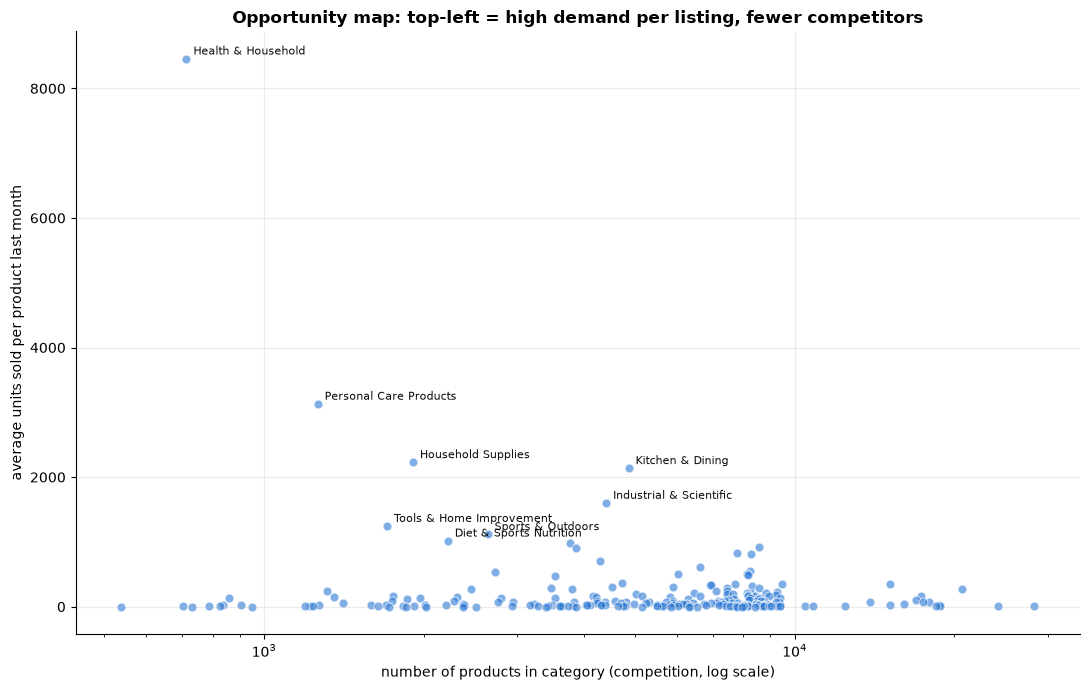

In [16]:
fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(big["products"], big["avg_monthly_sales"], s=40, color=BLUE, alpha=0.6,
           edgecolor="white", linewidth=0.8)
for name, r in big.nlargest(8, "avg_monthly_sales").iterrows():
    ax.annotate(name[:30], (r["products"], r["avg_monthly_sales"]), fontsize=8,
                xytext=(5, 3), textcoords="offset points", color="#0b0b0b")
ax.set_xscale("log")
ax.set_xlabel("number of products in category (competition, log scale)")
ax.set_ylabel("average units sold per product last month")
ax.set_title("Opportunity map: top-left = high demand per listing, fewer competitors")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "opportunity_map.png", dpi=120)
plt.show()

### Sales vs. price
Do cheaper products sell more often? We group products into **price bands** and compare.

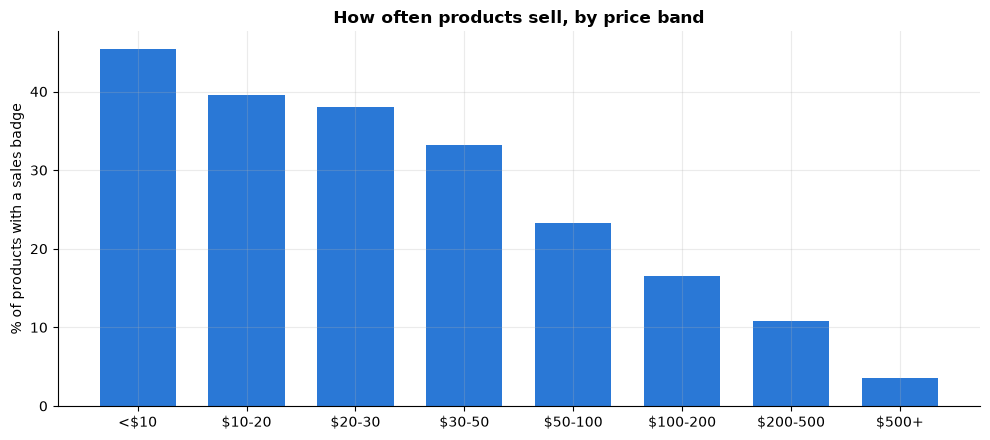

Average monthly sales - Best Seller badge: 2,336 units vs. no badge: 130 units


,products,pct_with_sales,avg_monthly_sales
price_band,,,
<$10,271304,45.39,218.96
$10-20,455974,39.52,155.04
$20-30,244494,38.06,142.24
$30-50,190023,33.23,119.73
$50-100,124589,23.31,71.70
$100-200,67213,16.58,43.41
$200-500,29515,10.75,27.96
$500+,10453,3.56,6.96


In [17]:
price_band = pd.cut(clean["price"], [0, 10, 20, 30, 50, 100, 200, 500, np.inf],
                    labels=["<$10", "$10-20", "$20-30", "$30-50", "$50-100", "$100-200", "$200-500", "$500+"])
by_price = (clean.assign(has_sales=clean["boughtInLastMonth"] > 0, price_band=price_band)
                 .groupby("price_band", observed=True)
                 .agg(products=("asin", "size"),
                      pct_with_sales=("has_sales", "mean"),
                      avg_monthly_sales=("boughtInLastMonth", "mean")))
by_price["pct_with_sales"] *= 100

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(by_price.index.astype(str), by_price["pct_with_sales"], color=BLUE, width=0.7)
ax.set_ylabel("% of products with a sales badge")
ax.set_title("How often products sell, by price band")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "sales_by_price_band.png", dpi=120)
plt.show()

best_seller_avg = clean.groupby("isBestSeller")["boughtInLastMonth"].mean()
print(f"Average monthly sales - Best Seller badge: {best_seller_avg.get(1, float('nan')):,.0f} units "
      f"vs. no badge: {best_seller_avg.get(0, float('nan')):,.0f} units")
by_price

## 7. Features: what the model gets to look at

A **feature** is one input column the model uses to make a prediction. Good features are a big part of good ML, so we create a few new ones (this is called **feature engineering**):

| Feature | Meaning |
|---|---|
| `price` | current price |
| `discount_pct`, `has_discount` | how far below the "was" price it's selling |
| `stars`, `reviews`, `has_reviews` | rating, review count, and whether it has been rated yet |
| `title_length`, `title_words` | how long/detailed the listing title is |
| `cat_products` | how many products in its category (**competition**) |
| `cat_median_price`, `price_vs_category` | typical price in the category, and whether this product is cheaper (<1) or pricier (>1) than that |
| `cat_sales_encoded` | how well its category sells **on average** (built later, from training data only) |
| `title_score`, `brand_rate` | my teammate's features: how "top-seller-like" the title's words are, and the brand's track record (section 10) |
| `isBestSeller` | **not used by the main models.** Amazon awards the badge *based on sales*, so it gives away the answer |

**Leakage** means accidentally giving the model the answer. A model with leakage looks amazing in testing and fails in real life. `isBestSeller` is a clear case, so it's out. The rule for everything else: **nothing built from sales numbers may use the test rows.**

We train **two versions** so the comparison with my teammate is fair whichever inputs he uses:

| Version | Inputs | Why |
|---|---|---|
| **No badge** | everything above except `isBestSeller` | removes the leak but keeps reviews and stars |
| **Launch-time only** | price, discount, title stats, title score & brand, category stats | only what a seller knows *before* launching, so it's the most honest test for MarketLens |

In [18]:
model_df = clean.copy()                           # keeps the title text: the title score (section 10) reads it

model_df["title_length"] = clean["title"].str.len()
model_df["title_words"] = clean["title"].str.count(r"\S+")     # counts words
model_df["discount_pct"] = (model_df["listPrice"] - model_df["price"]) / model_df["listPrice"] * 100
model_df["has_discount"] = (model_df["discount_pct"] > 0).astype(int)

# Market-level features. These use only product info (never sales), so computing them on all rows is safe.
model_df["cat_products"] = model_df.groupby("category_name")["asin"].transform("size")
model_df["cat_median_price"] = model_df.groupby("category_name")["price"].transform("median")
model_df["price_vs_category"] = model_df["price"] / model_df["cat_median_price"]

# Log of sales: used for the category feature below and for my first model (appendix)
model_df["log_sales"] = np.log1p(model_df["boughtInLastMonth"])

ALL_FEATURES = ["price", "discount_pct", "has_discount", "stars", "reviews", "has_reviews", "isBestSeller",
                "title_length", "title_words", "cat_products", "cat_median_price", "price_vs_category",
                "cat_sales_encoded"]                                               # appendix only
FEATURES_NO_BADGE = [f for f in ALL_FEATURES if f != "isBestSeller"]
LAUNCH_FEATURES = [f for f in ALL_FEATURES if f not in ["stars", "reviews", "has_reviews", "isBestSeller"]]
V1_LAUNCH_FEATURES = list(LAUNCH_FEATURES)                                         # appendix only

TITLE_FEATURES = ["title_score", "brand_rate"]     # built in section 10
if USE_TITLE_FEATURES:
    FEATURES_NO_BADGE += TITLE_FEATURES
    LAUNCH_FEATURES += TITLE_FEATURES

print("No badge (", len(FEATURES_NO_BADGE), "):", ", ".join(FEATURES_NO_BADGE))
print("Launch-time only (", len(LAUNCH_FEATURES), "):", ", ".join(LAUNCH_FEATURES))

No badge ( 14 ): price, discount_pct, has_discount, stars, reviews, has_reviews, title_length, title_words, cat_products, cat_median_price, price_vs_category, cat_sales_encoded, title_score, brand_rate
Launch-time only ( 11 ): price, discount_pct, has_discount, title_length, title_words, cat_products, cat_median_price, price_vs_category, cat_sales_encoded, title_score, brand_rate


## 8. The target: is it a top-20% seller *in its own category*?

This is the **team's shared target**, the same thing my teammate's model predicts:
> **1** = the product's monthly sales put it in the **top 20% of its own category**. **0** = everyone else.

**Why this target instead of raw sales (my first approach, in the appendix)?**
- **It takes the category effect out.** Every category has its own top 20%, so the model can't score well just by knowing "Toys sell more than Sewing". It has to tell products apart *inside* a niche, which is what a seller needs once they've picked one.
- **It's the same target as my teammate's**, so we can score both models with the same metrics.

**The tie rule matters.** Most products show 0 sales, and sales come in badge buckets (50, 100, 200, ...), so many products tie at the cutoff. Our rule:
- **Top seller** = sales **at or above** its category's 80th percentile **and above 0**. A product with no sales badge can't be a top seller.
- In categories where fewer than 20% of products sell at all, **fewer than 20%** are labeled top. In categories with lots of ties at the cutoff, **slightly more** are.

If my teammate's rule is different, change the line marked `<- the label rule` (or `TOP_SHARE` in Setup), then compare our label files (saved in section 14).

In [19]:
cutoff = model_df.groupby("category_name")["boughtInLastMonth"].transform(lambda s: s.quantile(1 - TOP_SHARE))
model_df["is_top20"] = ((model_df["boughtInLastMonth"] >= cutoff) & (model_df["boughtInLastMonth"] > 0)).astype(int)  # <- the label rule
LABEL = "is_top20"

share_by_cat = model_df.groupby("category_name")[LABEL].mean() * 100
print(f"Products labeled top-20%: {model_df[LABEL].mean():.1%} of all products")
print(f"Per category: median {share_by_cat.median():.1f}%, lowest {share_by_cat.min():.1f}%, highest {share_by_cat.max():.1f}%")
print(f"Categories with fewer than 20% labeled top (most of their products show no sales badge): "
      f"{(share_by_cat < 19.5).sum()} of {len(share_by_cat)}")

# What does a typical top seller look like vs. everyone else? (medians)
(model_df.groupby(LABEL)[["price", "discount_pct", "reviews", "stars", "price_vs_category", "title_length"]]
         .median()
         .rename(index={0: "not top", 1: "top 20%"}))

Products labeled top-20%: 18.4% of all products
Per category: median 18.4%, lowest 0.0%, highest 67.5%
Categories with fewer than 20% labeled top (most of their products show no sales badge): 128 of 248


,price,discount_pct,reviews,stars,price_vs_category,title_length
is_top20,,,,,,
not top,19.99,0.00,0.00,4.40,1.01,122.00
top 20%,17.70,0.00,0.00,4.50,0.91,132.00


## 9. Train/test split

We hide **20% of products** from the model while it learns (the **test set**). After training, we score it on those hidden products. That's the only fair way to know if it works on products it has never seen, which is exactly what MarketLens will face.

- **My teammate's split file** (`split_for_vishal.csv`, columns `asin`, `split`) is used automatically when it's in `data/` (`SPLIT_FILE` in Setup). That trains on about 1M products and tests on his ~250,000, so both models are graded on **the same products**.
- Without that file, it falls back to my own 300,000-product random sample (`random_state=42` makes it identical every run).
- `cat_sales_encoded` replaces the category name with "how well this category sells on average" (**target encoding**). Three safeguards against leakage:
  1. Test products get category averages calculated **only from training products**.
  2. Inside the training set we use **5-fold out-of-fold encoding**: split the training rows into 5 parts, and fill each part using averages from the *other 4*. A product's own sales never feed into its own feature.
  3. **Smoothing:** small categories get pulled toward the overall average, so a category with 3 lucky products doesn't look like a goldmine.

In [20]:
use_split_file = SPLIT_FILE is not None and Path(SPLIT_FILE).exists()
if SPLIT_FILE is not None and not use_split_file:
    print(f"Split file {SPLIT_FILE} not found - using my own random sample instead.")

if use_split_file:
    split_map = pd.read_csv(SPLIT_FILE).drop_duplicates("asin").set_index("asin")["split"]
    data = model_df[model_df["asin"].isin(split_map.index)]
    train_df = data[data["asin"].map(split_map) == "train"].copy()
    test_df = data[data["asin"].map(split_map) == "test"].copy()
    print(f"Using the train/test split from {SPLIT_FILE}: {len(data):,} of its {len(split_map):,} products "
          f"are in my cleaned data")
else:
    data = model_df
    if MODEL_SAMPLE_SIZE is not None and len(data) > MODEL_SAMPLE_SIZE:
        data = data.sample(MODEL_SAMPLE_SIZE, random_state=RANDOM_STATE)
        print(f"Using a random sample of {MODEL_SAMPLE_SIZE:,} products (change MODEL_SAMPLE_SIZE in Setup)")
    train_df, test_df = train_test_split(data, test_size=0.2, random_state=RANDOM_STATE)
    train_df, test_df = train_df.copy(), test_df.copy()

def category_averages(rows, target="log_sales", smoothing=20):
    """Average log-sales per category, pulled toward the overall average for small categories."""
    overall_avg = rows[target].mean()
    stats = rows.groupby("category_name")[target].agg(["mean", "count"])
    return (stats["mean"] * stats["count"] + overall_avg * smoothing) / (stats["count"] + smoothing)

# Training rows: out-of-fold (each fold is filled using the other 4 folds)
train_df["cat_sales_encoded"] = np.nan
for fit_idx, fill_idx in KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(train_df):
    averages = category_averages(train_df.iloc[fit_idx])
    fill_rows = train_df.index[fill_idx]
    train_df.loc[fill_rows, "cat_sales_encoded"] = train_df.loc[fill_rows, "category_name"].map(averages)

# Test rows: averages from ALL training rows (never from test rows)
test_df["cat_sales_encoded"] = test_df["category_name"].map(category_averages(train_df))

# A category never seen in training gets the overall training average
train_df["cat_sales_encoded"] = train_df["cat_sales_encoded"].fillna(train_df["log_sales"].mean())
test_df["cat_sales_encoded"] = test_df["cat_sales_encoded"].fillna(train_df["log_sales"].mean())

y_train, y_test = train_df[LABEL], test_df[LABEL]
print(f"Training rows: {len(train_df):,}   |   Test rows: {len(test_df):,}   |   "
      f"Top-20% share in test: {y_test.mean():.1%}")

Using the train/test split from data/split_for_vishal.csv: 1,249,285 of its 1,249,285 products are in my cleaned data
Training rows: 999,428   |   Test rows: 249,857   |   Top-20% share in test: 18.5%


## 10. Title score and brand track record (my teammate's features)

My teammate's XGBoost had two inputs my model didn't have. His title score was his #1 feature. To compare **Random Forest vs. XGBoost fairly**, both models now get the same inputs. This is his code, unchanged except for comments.

- **`title_score`**: how much a product's title "sounds like" a top seller's title.
  1. Break each title into words and 2-word phrases ("stainless steel", "pack of").
  2. **TF-IDF** weights each one by how distinctive it is. Words that appear in nearly every title, like "for", count less.
  3. A **logistic regression** (a simple yes/no model) learns from the training products which words and phrases show up more in top sellers' titles.
  4. Each title gets a score. Higher = more like the titles of top sellers.
- **`brand_rate`**: the brand's track record, meaning the share of its products that are top-20% sellers. The brand is the first word of the title, which on Amazon is usually the brand. Small brands get pulled toward the average, so a brand with 3 products can't look like a goldmine.

**Leak safety:** the same idea as `cat_sales_encoded`. Training rows get scores from models fit on the *other* 4 of 5 folds. Test rows are scored by a model fit on training rows only.

**Worth mentioning to mentors:**
- `brand_rate` assumes the brand already sells on Amazon. A brand-new brand has no track record, so it just gets the average.
- Variants of the same product (different sizes or colors have different ASINs) can land in both train and test. Their titles and brand are nearly identical, so these two inputs may look a bit stronger than they would for a truly new product. Since we use the same split, this affects both our models equally.

This trains the text model 6 times, so expect several minutes on about 1M products. Set `USE_TITLE_FEATURES = False` in Setup to skip it.

In [21]:
def brand_of(title):
    # The first word of an Amazon title is usually the brand ("Samsonite Winfield 2 ...").
    first = re.split(r"[\s,|(\-]+", title.strip(), maxsplit=1)[0] if title else ""
    return re.sub(r"[^a-z0-9&']", "", first.lower())

def fit_and_score(train_titles, train_brands, train_y, pred_titles, pred_brands, prior):
    # Words + 2-word phrases -> TF-IDF weights. Hashing keeps memory flat on a laptop (no giant word list).
    vec = make_pipeline(
        HashingVectorizer(ngram_range=(1, 2), n_features=2**20, alternate_sign=False,
                          norm=None, dtype=np.float32),
        TfidfTransformer(sublinear_tf=True))
    # Logistic regression: which words/phrases show up more in top sellers' titles
    clf = SGDClassifier(loss="log_loss", alpha=2e-6, max_iter=20, tol=None,
                        random_state=RANDOM_STATE)
    clf.fit(vec.fit_transform(train_titles), train_y)
    title_score = clf.decision_function(vec.transform(pred_titles))

    # Smoothed brand success rate: a brand with 3 products can't look like a goldmine.
    stats = train_y.groupby(train_brands.values).agg(["sum", "count"])
    rate = (stats["sum"] + 20 * prior) / (stats["count"] + 20)
    brand_rate = pred_brands.map(rate).fillna(prior).values
    return title_score, brand_rate

if USE_TITLE_FEATURES:
    start = time.time()
    titles_tr = train_df["title"].fillna("").astype(str)
    titles_te = test_df["title"].fillna("").astype(str)
    brands_tr, brands_te = titles_tr.map(brand_of), titles_te.map(brand_of)
    y_tr = train_df[LABEL].astype(int)
    prior = y_tr.mean()

    # Training rows: out-of-fold (each fold is scored by a model fit on the other 4 folds)
    train_df["title_score"] = np.nan
    train_df["brand_rate"] = np.nan
    folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    for k, (fit_idx, fill_idx) in enumerate(folds.split(train_df, y_tr)):
        ts, br = fit_and_score(titles_tr.iloc[fit_idx], brands_tr.iloc[fit_idx], y_tr.iloc[fit_idx],
                               titles_tr.iloc[fill_idx], brands_tr.iloc[fill_idx], prior)
        train_df.iloc[fill_idx, train_df.columns.get_loc("title_score")] = ts
        train_df.iloc[fill_idx, train_df.columns.get_loc("brand_rate")] = br
        print(f"title score: fold {k + 1}/5 done")

    # Test rows: model fit on ALL training rows (never on test rows)
    ts, br = fit_and_score(titles_tr, brands_tr, y_tr, titles_te, brands_te, prior)
    test_df["title_score"] = ts
    test_df["brand_rate"] = br
    print(f"Added title_score and brand_rate in {time.time() - start:.0f} seconds "
          f"({brands_tr.nunique():,} distinct brands in training)")
else:
    print("Skipped: USE_TITLE_FEATURES = False")

title score: fold 1/5 done
title score: fold 2/5 done
title score: fold 3/5 done
title score: fold 4/5 done
title score: fold 5/5 done
Added title_score and brand_rate in 68 seconds (92,522 distinct brands in training)


## 11. How we score the models, and the scores to beat

The model outputs a **score from 0 to 1** for each product: its estimated chance of being a top-20% seller. We judge how well those scores **rank** the real top sellers above everyone else. These are my teammate's metrics, plus one extra:

| Metric | Plain meaning | Coin flip scores |
|---|---|---|
| **ROC-AUC** | Pick one real top seller and one other product at random. ROC-AUC is the chance the model gives the top seller the higher score. 1.0 = always right | **0.5** |
| **PR-AUC** | When the model flags products as "likely top", how often it's right, averaged over every cutoff. Stricter than ROC-AUC when top sellers are rare | **the share of top sellers** (shown in section 9), *not* 0 |
| **ROC-AUC within category** | ROC-AUC calculated separately inside each category, then averaged. This is exactly the seller's question: *inside my niche, which products win?* | **0.5** |

**Baselines** (simple rules the Random Forest has to beat):
- **Coin flip:** no information at all.
- **Category only:** score each product by how often its category produces top sellers. It can't rank anything *inside* a category, so its within-category score is 0.5 by design.
- **Sort by reviews:** the rule of thumb "the most-reviewed products are the top sellers". If the Random Forest can't beat this, it isn't worth it.
- **Title score alone:** my teammate's text model on its own (section 10). It shows how much the Random Forest adds on top of the title score.

In [22]:
def within_category_auc(rows, scores, min_rows=30):
    """ROC-AUC inside each category (that has enough products and both classes), weighted by category size."""
    aucs, weights = [], []
    for _, idx in rows.groupby("category_name").groups.items():
        y = rows.loc[idx, LABEL]
        if len(y) >= min_rows and y.nunique() == 2:
            aucs.append(roc_auc_score(y, scores.loc[idx]))
            weights.append(len(y))
    return np.average(aucs, weights=weights) if aucs else np.nan

def evaluate_clf(name, scores):
    scores = pd.Series(np.asarray(scores, dtype=float), index=test_df.index)
    return {"model": name,
            "ROC-AUC": roc_auc_score(y_test, scores),
            "PR-AUC": average_precision_score(y_test, scores),
            "ROC-AUC within category": within_category_auc(test_df, scores)}

clf_results = []
clf_results.append(evaluate_clf("Baseline: coin flip", np.zeros(len(test_df))))
category_rate = train_df.groupby("category_name")[LABEL].mean()
clf_results.append(evaluate_clf("Baseline: category only",
                                test_df["category_name"].map(category_rate).fillna(y_train.mean())))
clf_results.append(evaluate_clf("Baseline: sort by reviews", test_df["reviews"]))
if USE_TITLE_FEATURES:
    clf_results.append(evaluate_clf("Baseline: title score alone", test_df["title_score"]))
pd.DataFrame(clf_results).set_index("model").round(3)

,ROC-AUC,PR-AUC,ROC-AUC within category
model,,,
Baseline: coin flip,0.50,0.18,0.50
Baseline: category only,0.69,0.32,0.50
Baseline: sort by reviews,0.52,0.24,0.56
Baseline: title score alone,0.77,0.42,0.72


## 12. Random Forest (classifier)

**How it works, in plain words:** a **decision tree** is a flowchart of yes/no questions ("Has reviews? → Cheaper than the category's typical price? → ..."). One tree **overfits**: it memorizes quirks of the training data. A **Random Forest** grows many trees (here, 100). Each tree sees a **random sample of products** and a **random subset of features** at each question. For a yes/no target, each tree votes "top" or "not top", and **the share of trees voting "top" is the product's score**. The trees make different mistakes that mostly cancel out.

**Settings, kept close to the defaults on purpose:** `n_estimators=100` trees · `min_samples_leaf=MIN_SAMPLES_LEAF` (50 by default: every final answer is based on at least 50 products, which also keeps training on about 1M products fast enough) · `max_features=0.5` (each question considers a random half of the features) · `n_jobs=-1` (use every CPU core).

We train it twice, once per feature set. Expect roughly 5–15 minutes in total on about 1M products.

In [23]:
def make_forest():
    return RandomForestClassifier(n_estimators=100, min_samples_leaf=MIN_SAMPLES_LEAF, max_features=0.5,
                                  n_jobs=-1, random_state=RANDOM_STATE)

MAIN = "Random Forest (no badge)"
LAUNCH = "Random Forest (launch-time only)"
models, test_scores = {}, {}
for name, feats in [(MAIN, FEATURES_NO_BADGE), (LAUNCH, LAUNCH_FEATURES)]:
    start = time.time()
    m = make_forest().fit(train_df[feats], y_train)
    models[name] = (m, feats)
    test_scores[name] = m.predict_proba(test_df[feats])[:, 1]       # column 1 = chance of "top"
    clf_results.append(evaluate_clf(name, test_scores[name]))
    print(f"{name:<34} trained in {time.time() - start:.0f} seconds")

clf_table = pd.DataFrame(clf_results).set_index("model")
clf_table.round(3)

Random Forest (no badge)           trained in 22 seconds
Random Forest (launch-time only)   trained in 18 seconds


,ROC-AUC,PR-AUC,ROC-AUC within category
model,,,
Baseline: coin flip,0.50,0.18,0.50
Baseline: category only,0.69,0.32,0.50
Baseline: sort by reviews,0.52,0.24,0.56
Baseline: title score alone,0.77,0.42,0.72
Random Forest (no badge),0.83,0.54,0.80
Random Forest (launch-time only),0.80,0.48,0.75


### Overfitting check
Compare ROC-AUC on the products the model **trained on** with ROC-AUC on the **hidden test products**. A small gap is normal. A huge gap means the model memorized instead of learning.

In [24]:
for name, (m, feats) in models.items():
    auc_train = roc_auc_score(y_train, m.predict_proba(train_df[feats])[:, 1])
    auc_test = clf_table.loc[name, "ROC-AUC"]
    print(f"{name:<34} train ROC-AUC {auc_train:.3f}  |  test {auc_test:.3f}  |  gap {auc_train - auc_test:.3f}")

Random Forest (no badge)           train ROC-AUC 0.872  |  test 0.834  |  gap 0.038
Random Forest (launch-time only)   train ROC-AUC 0.846  |  test 0.801  |  gap 0.045


## 13. Results

### Model comparison
Bars are the models on the same hidden test products, and higher is better. The dashed line is my teammate's XGBoost (full version). The next chart compares both versions side by side.

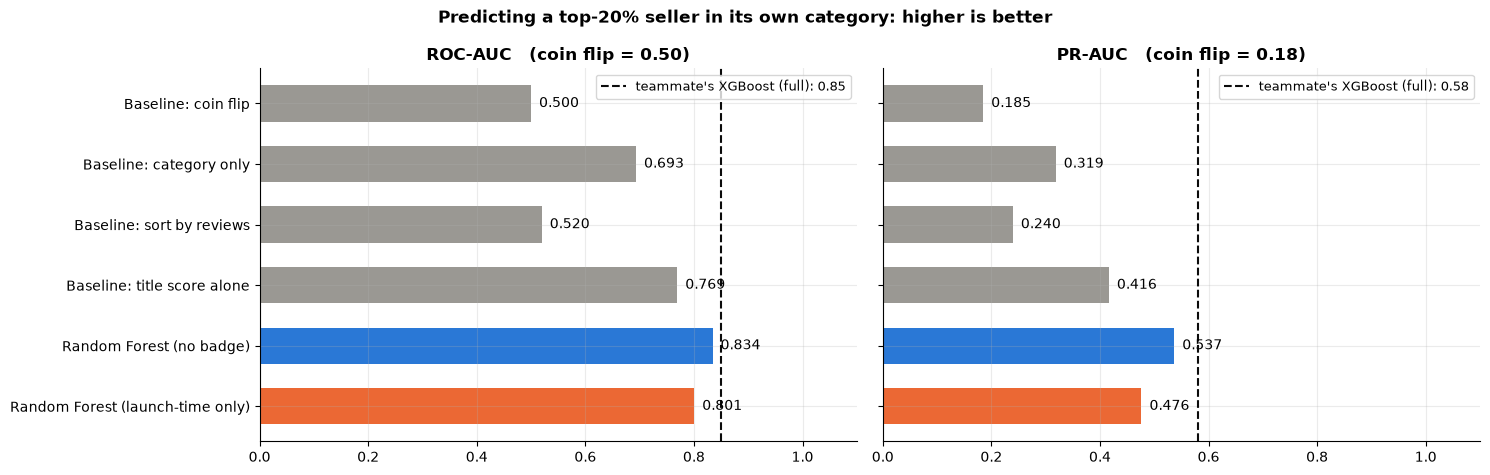

,ROC-AUC,PR-AUC,ROC-AUC within category
model,,,
Baseline: coin flip,0.50,0.18,0.50
Baseline: category only,0.69,0.32,0.50
Baseline: sort by reviews,0.52,0.24,0.56
Baseline: title score alone,0.77,0.42,0.72
Random Forest (no badge),0.83,0.54,0.80
Random Forest (launch-time only),0.80,0.48,0.75


In [25]:
colors = {name: GRAY for name in clf_table.index}
colors[MAIN], colors[LAUNCH] = BLUE, ORANGE
order = clf_table.index[::-1]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for ax, metric in zip(axes, ["ROC-AUC", "PR-AUC"]):
    vals = clf_table.loc[order, metric]
    ax.barh(order, vals, color=[colors[n] for n in order], height=0.6)
    for y, v in enumerate(vals):
        ax.text(v, y, f"  {v:.3f}", va="center", fontsize=10)
    theirs = TEAMMATE_SCORES.get("full", {}).get(metric)
    if theirs is not None:
        ax.axvline(theirs, color="#0b0b0b", linestyle="--", linewidth=1.5,
                   label=f"teammate's XGBoost (full): {theirs:.2f}")
        ax.legend(loc="upper right", fontsize=9)
    ax.set_xlim(0, 1.1)
    coin = 0.5 if metric == "ROC-AUC" else y_test.mean()
    ax.set_title(f"{metric}   (coin flip = {coin:.2f})")
plt.suptitle("Predicting a top-20% seller in its own category: higher is better", fontweight="bold")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "model_comparison.png", dpi=120)
plt.show()
clf_table.round(3)

### My Random Forest vs. my teammate's XGBoost
Same target, same test products, same inputs (including his title score and brand). Whatever gap is left comes mostly from the **algorithm**:
- **XGBoost** builds trees one after another, each one fixing the previous trees' mistakes.
- **Random Forest** builds many independent trees and averages them.

The dashed line is the category-only baseline.

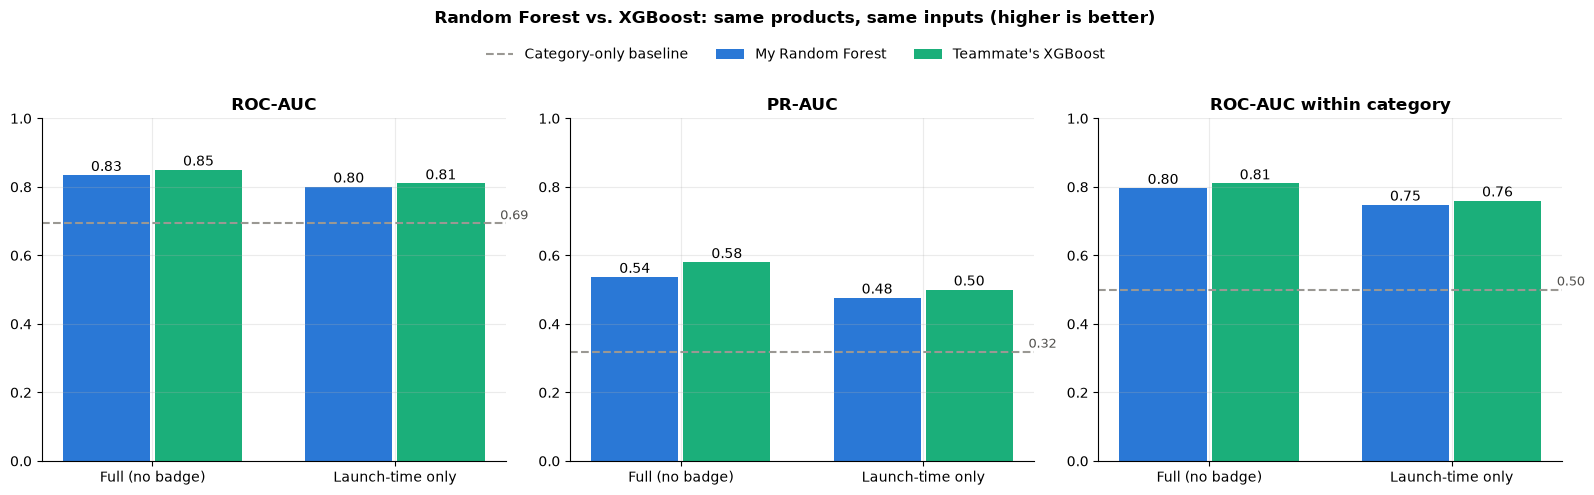

In [26]:
versions = [("Full (no badge)", MAIN, "full"), ("Launch-time only", LAUNCH, "launch-time")]
metrics = ["ROC-AUC", "PR-AUC", "ROC-AUC within category"]
x, w = np.arange(len(versions)), 0.36

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, metric in zip(axes, metrics):
    rf_vals = [clf_table.loc[model, metric] for _, model, _ in versions]
    xgb_vals = [TEAMMATE_SCORES.get(key, {}).get(metric, np.nan) for _, _, key in versions]
    for offset, vals, color, label in [(-w / 2 - 0.01, rf_vals, BLUE, "My Random Forest"),
                                       (w / 2 + 0.01, xgb_vals, AQUA, "Teammate's XGBoost")]:
        bars = ax.bar(x + offset, vals, w, color=color, label=label)
        for b, v in zip(bars, vals):
            if not np.isnan(v):
                ax.text(b.get_x() + b.get_width() / 2, v + 0.012, f"{v:.2f}", ha="center", fontsize=10)
    base = clf_table.loc["Baseline: category only", metric]
    ax.axhline(base, color=GRAY, linestyle="--", linewidth=1.5, label="Category-only baseline")
    ax.text(x[-1] + 0.55, base + 0.012, f"{base:.2f}", ha="right", fontsize=9, color="#52514e")
    ax.set_xticks(x, [v for v, _, _ in versions])
    ax.set_ylim(0, 1)
    ax.set_title(metric)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.93), frameon=False)
fig.suptitle("Random Forest vs. XGBoost: same products, same inputs (higher is better)", fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.9])
plt.savefig(RESULTS_DIR / "rf_vs_xgboost.png", dpi=120)
plt.show()

### ROC and precision-recall curves
These show the trade-off behind each score, for the two Random Forests.
- **ROC curve (left):** the more it bows toward the **top-left**, the better. The dashed diagonal is a coin flip.
- **Precision-recall curve (right):** as the model flags more products as "top" (moving right), it catches more real top sellers but makes more false alarms (the line drops). **Higher is better.** The dashed line is a coin flip.

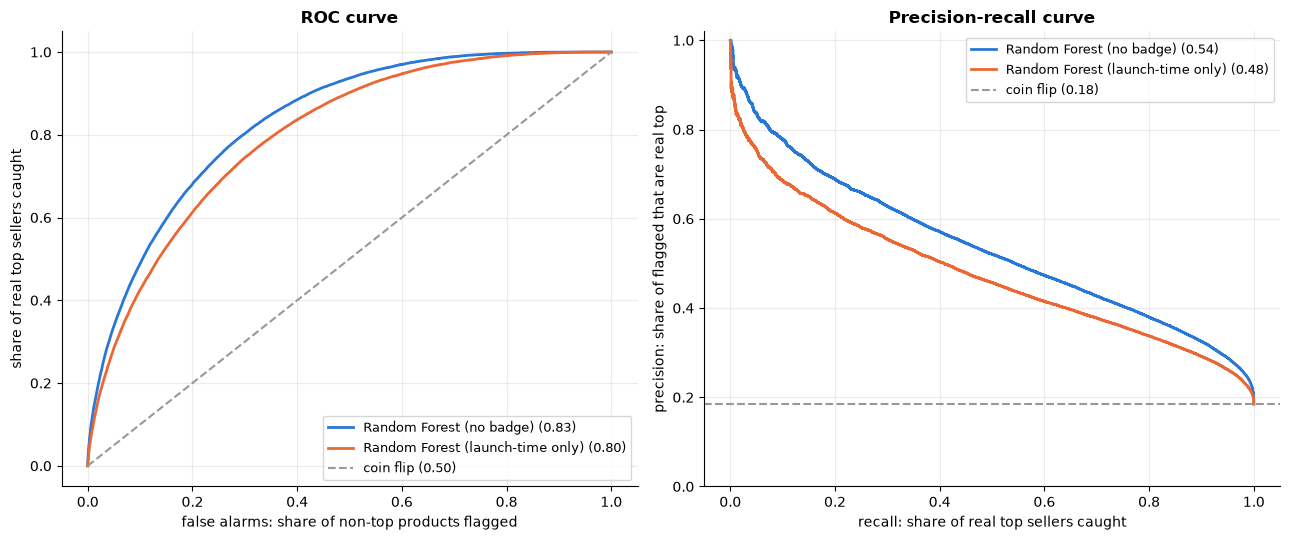

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for name in [MAIN, LAUNCH]:
    fpr, tpr, _ = roc_curve(y_test, test_scores[name])
    precision, recall, _ = precision_recall_curve(y_test, test_scores[name])
    axes[0].plot(fpr, tpr, color=colors[name], linewidth=2, label=f"{name} ({clf_table.loc[name, 'ROC-AUC']:.2f})")
    axes[1].plot(recall, precision, color=colors[name], linewidth=2, label=f"{name} ({clf_table.loc[name, 'PR-AUC']:.2f})")
axes[0].plot([0, 1], [0, 1], color=GRAY, linestyle="--", label="coin flip (0.50)")
axes[1].axhline(y_test.mean(), color=GRAY, linestyle="--", label=f"coin flip ({y_test.mean():.2f})")
axes[0].set(xlabel="false alarms: share of non-top products flagged", ylabel="share of real top sellers caught",
            title="ROC curve")
axes[1].set(xlabel="recall: share of real top sellers caught", ylabel="precision: share of flagged that are real top",
            title="Precision-recall curve", ylim=(0, 1.02))
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "upper right", fontsize=9)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "roc_pr_curves.png", dpi=120)
plt.show()

### What drives a top seller? (feature importance)
**Permutation importance:** shuffle one input's values in the test set and measure how much ROC-AUC drops. A big drop means the model really relies on that input. This is shown for the main model (no badge).

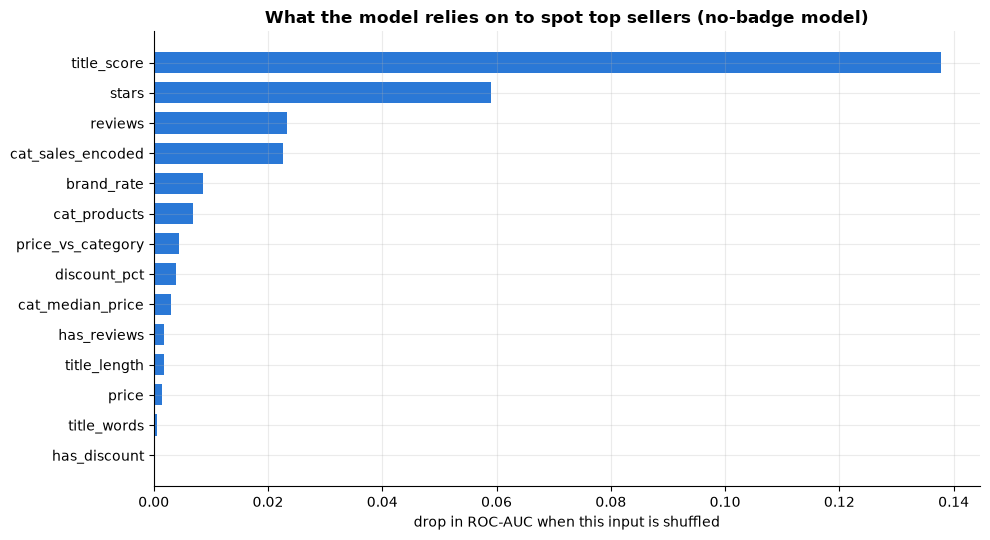

title_score         0.1377
stars               0.0590
reviews             0.0233
cat_sales_encoded   0.0227
brand_rate          0.0087
cat_products        0.0069
price_vs_category   0.0044
discount_pct        0.0039
cat_median_price    0.0030
has_reviews         0.0018
title_length        0.0017
price               0.0015
title_words         0.0006
has_discount        0.0001


In [28]:
main_model, main_feats = models[MAIN]
sample = test_df.sample(min(20_000, len(test_df)), random_state=RANDOM_STATE)
perm = permutation_importance(main_model, sample[main_feats], sample[LABEL], scoring="roc_auc",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=main_feats).sort_values()

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(importance.index, importance.values, color=BLUE, height=0.7)
ax.set_xlabel("drop in ROC-AUC when this input is shuffled")
ax.set_title("What the model relies on to spot top sellers (no-badge model)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "rf_feature_importance.png", dpi=120)
plt.show()
importance = importance.sort_values(ascending=False)
print(importance.to_string(float_format=lambda v: f"{v:.4f}"))

### Does it rank products inside a niche?
A concrete example a seller would recognize: take the **biggest category** in the test set, let the model pick its **top 10** products, and check how many are real top-20% sellers.

In [29]:
test_df["model_score"] = test_scores[MAIN]
biggest = test_df["category_name"].value_counts().index[0]
in_cat = test_df[test_df["category_name"] == biggest]
picks = in_cat.nlargest(10, "model_score")
expected = in_cat[LABEL].mean() * 10
print(f"Category: {biggest}  ({len(in_cat):,} test products, {in_cat[LABEL].mean():.0%} are top sellers)")
print(f"Model's top 10 picks: {picks[LABEL].sum()} of 10 are real top-20% sellers  "
      f"(10 random picks would get about {expected:.1f})")
(picks.assign(title=clean.loc[picks.index, "title"].str[:60])
      [["title", "price", "reviews", "stars", "boughtInLastMonth", LABEL, "model_score"]])

Category: Girls' Clothing  (5,092 test products, 10% are top sellers)
Model's top 10 picks: 10 of 10 are real top-20% sellers  (10 random picks would get about 1.0)


,title,price,reviews,stars,boughtInLastMonth,is_top20,model_score
76958,girls Princess Underwear Multipacks With Favor...,9.89,14538,4.70,2000,1,0.88
77249,Girls' Short Sleeve Picot Collar Polo School U...,9.72,11065,4.70,200,1,0.87
77124,Girls' 100% Combed Cotton 10-Pack Underwear Av...,12.99,5732,4.70,200,1,0.86
76993,Girls' Big 2 Pack Knee High Socks,5.39,4880,4.70,700,1,0.86
76401,"Unisex Kids and Toddlers' Cotton Low Cut Sock,...",16.10,26396,4.60,2000,1,0.85
76522,Girls' Cotton Bikini Underwear Multipacks,11.75,22037,4.70,900,1,0.85
76879,"Girls and Toddlers' Tank Top, Multipacks",12.72,4632,4.40,200,1,0.84
223149,Girls' Pull-on Short (Standard & Plus),10.99,4982,4.50,100,1,0.83
223084,Girls' 100% Combed Cotton Underwear Panties in...,12.40,3979,4.70,200,1,0.82
223028,Girls and Toddlers' Fleece Zip-Up Hoodie Sweat...,17.30,11549,4.70,100,1,0.82


### Fair comparison checklist (with my teammate)
For his scores and mine to be directly comparable, all four must match:

| Must match | Status |
|---|---|
| **1. Label rule** | **Done.** My category-only baseline matched his exactly (0.69 / 0.32 / 0.50) on his split. To check row by row, put his labels in `data/teammate_labels.csv` (columns `asin`, `label`) and the cell below compares them |
| **2. Test products** | **Done.** Using his split file (`split_for_vishal.csv`) |
| **3. Inputs** | **Done for title and brand** (section 10). Worth confirming the rest of his feature list matches mine |
| **4. Metrics** | **Done.** ROC-AUC, PR-AUC and within-category ROC-AUC |

In [30]:
TEAMMATE_LABEL_FILE = DATA_DIR / "teammate_labels.csv"     # optional: columns asin, label

if TEAMMATE_LABEL_FILE.exists():
    theirs = pd.read_csv(TEAMMATE_LABEL_FILE).drop_duplicates("asin").set_index("asin")["label"]
    mine = model_df.set_index("asin")[LABEL]
    both = mine.index.intersection(theirs.index)
    match = (mine.loc[both] == theirs.loc[both]).mean()
    print(f"Products in both files: {len(both):,}")
    print(f"Labels that match: {match:.2%}  ->  {'same target' if match >= 0.99 else 'DIFFERENT target - align the label rule first'}")
    print(f"Share labeled top - mine: {mine.loc[both].mean():.1%}, teammate: {theirs.loc[both].mean():.1%}")
else:
    print(f"No teammate label file found at {TEAMMATE_LABEL_FILE} (optional).")
    print("The matching category-only baseline already suggests our labels line up.")

No teammate label file found at data/teammate_labels.csv (optional).
The matching category-only baseline already suggests our labels line up.


## 14. Meeting summary & saved results

The next cell writes the key findings as plain sentences, using **your real numbers**. Read it before the meeting. The cell after that saves everything into `results/` for the team.

In [31]:
rf, launch = clf_table.loc[MAIN], clf_table.loc[LAUNCH]
cat_only = clf_table.loc["Baseline: category only"]
removed = len(df) - len(clean)
top_feats = importance.index[:3].tolist()
nan = float("nan")

# My previous run on the same split, BEFORE adding the title features (Oct 14)
RF_WITHOUT_TITLE = {MAIN:   {"ROC-AUC": 0.806, "PR-AUC": 0.489, "ROC-AUC within category": 0.745},
                    LAUNCH: {"ROC-AUC": 0.746, "PR-AUC": 0.400, "ROC-AUC within category": 0.649}}

def fmt(name, s):
    g = lambda m: s.get(m, nan)
    return f"  {name:<38} {g('ROC-AUC'):>7.3f} {g('PR-AUC'):>7.3f} {g('ROC-AUC within category'):>10.3f}"

def gap_words(mine, theirs):
    if theirs is None or np.isnan(theirs):
        return "no teammate score"
    diff = mine - theirs
    return "about even" if abs(diff) < 0.01 else f"RF {'ahead' if diff > 0 else 'behind'} by {abs(diff):.2f}"

def teammate_pair(key):
    t = TEAMMATE_SCORES.get(key, {})
    return f"{t.get('ROC-AUC', nan):.2f} / {t.get('PR-AUC', nan):.2f}"

lines = "\n".join(fmt(name, r.to_dict()) for name, r in clf_table.iterrows())
lines += "\n" + fmt("Teammate XGBoost (full)", TEAMMATE_SCORES.get("full", {}))
lines += "\n" + fmt("Teammate XGBoost (launch-time)", TEAMMATE_SCORES.get("launch-time", {}))

versus = "\n".join(
    f"  - {label}: ROC-AUC {gap_words(mine['ROC-AUC'], TEAMMATE_SCORES.get(key, {}).get('ROC-AUC'))}, "
    f"PR-AUC {gap_words(mine['PR-AUC'], TEAMMATE_SCORES.get(key, {}).get('PR-AUC'))}, "
    f"within-category {gap_words(mine['ROC-AUC within category'], TEAMMATE_SCORES.get(key, {}).get('ROC-AUC within category'))}"
    for label, mine, key in [("Full (no badge)", rf, "full"), ("Launch-time", launch, "launch-time")])

if USE_TITLE_FEATURES:
    title_words = (f"- Adding his title score + brand rate moved my RF from ROC-AUC {RF_WITHOUT_TITLE[MAIN]['ROC-AUC']:.2f} to "
                   f"{rf['ROC-AUC']:.2f} (full) and from {RF_WITHOUT_TITLE[LAUNCH]['ROC-AUC']:.2f} to {launch['ROC-AUC']:.2f} (launch-time).\n"
                   f"  The title score on its own gets ROC-AUC {clf_table.loc['Baseline: title score alone', 'ROC-AUC']:.2f}.")
else:
    title_words = "- Title features were switched off for this run (USE_TITLE_FEATURES = False)."

def roc_gap(model, key):
    return clf_table.loc[model, "ROC-AUC"] - TEAMMATE_SCORES.get(key, {}).get("ROC-AUC", nan)

def side(g):
    return f"{'ahead' if g > 0 else 'behind'} by {abs(g):.2f}"

g_full, g_launch = roc_gap(MAIN, "full"), roc_gap(LAUNCH, "launch-time")
if np.isnan(g_full) or np.isnan(g_launch):
    verdict = "No teammate scores entered, so no head-to-head verdict yet."
elif g_full <= -0.01 and g_launch <= -0.01:
    verdict = (f"With the same products and inputs, XGBoost is still ahead in both versions ({-g_full:.2f} and {-g_launch:.2f} ROC-AUC), "
               "so the algorithm itself makes a difference here.")
elif g_full >= 0.01 and g_launch >= 0.01:
    verdict = (f"With the same products and inputs, my Random Forest is ahead in both versions ({g_full:.2f} and {g_launch:.2f} ROC-AUC), "
               "so the more complex XGBoost isn't buying extra accuracy here.")
elif abs(g_full) < 0.01 and abs(g_launch) < 0.01:
    verdict = ("With the same products and inputs, the two algorithms score about the same, so most of his earlier lead "
               "came from the title features, not from XGBoost itself.")
else:
    verdict = (f"Mixed result: my Random Forest is {side(g_full)} ROC-AUC on the full version but {side(g_launch)} on launch-time, "
               "so neither algorithm wins outright.")

if cat_only["ROC-AUC"] < 0.6:
    category_words = f"Category alone barely helps: ROC-AUC {cat_only['ROC-AUC']:.2f}, and 0.50 inside a category."
else:
    category_words = (f"Category alone gets ROC-AUC {cat_only['ROC-AUC']:.2f} overall (many categories have few top sellers),\n"
                      "  but 0.50 inside a category, so the within-category column is the cleanest test of ranking inside a niche.")

summary = f"""
MEETING SUMMARY - Random Forest vs. teammate's XGBoost (target = top 20% of its own category)
---------------------------------------------------------------------------------------------
DATA & CLEANING
- Started with {len(df):,} products; removed {removed:,} ({removed / len(df):.1%}) - duplicates and $0/missing prices.
- {(clean['boughtInLastMonth'] == 0).mean():.0%} of products show no "bought in past month" badge.
- {model_df[LABEL].mean():.1%} of products are labeled top-20% in their category. isBestSeller is not used (it leaks the answer).

SETUP
- Tested on {len(test_df):,} products, trained on {len(train_df):,} ({'teammate split file' if use_split_file else 'my own random sample'}).
- Inputs {'include' if USE_TITLE_FEATURES else 'do NOT include'} the teammate's title_score + brand_rate. Random Forest leaf size {MIN_SAMPLES_LEAF}.

RESULTS                                    ROC-AUC  PR-AUC  within-category
{lines}

WHAT IT MEANS
- {category_words}
{title_words}
- My Random Forest vs. his XGBoost:
{versus}
- {verdict}
- Most important inputs (full RF): {', '.join(top_feats)}.
- Caveat: brand_rate assumes the brand already sells on Amazon; a brand-new brand just gets the average.

WHAT TO SAY
"On the same {len(test_df):,} test products, with the same target and the same inputs (including his title score and
 brand track record), my Random Forest scores ROC-AUC {rf['ROC-AUC']:.2f} / PR-AUC {rf['PR-AUC']:.2f} vs. his XGBoost {teammate_pair('full')}.
 Launch-time only: {launch['ROC-AUC']:.2f} / {launch['PR-AUC']:.2f} vs. {teammate_pair('launch-time')}. {verdict}"
"""
(RESULTS_DIR / "meeting_summary.txt").write_text(summary)
print(summary)


MEETING SUMMARY - Random Forest vs. teammate's XGBoost (target = top 20% of its own category)
---------------------------------------------------------------------------------------------
DATA & CLEANING
- Started with 1,426,337 products; removed 32,772 (2.3%) - duplicates and $0/missing prices.
- 64% of products show no "bought in past month" badge.
- 18.4% of products are labeled top-20% in their category. isBestSeller is not used (it leaks the answer).

SETUP
- Tested on 249,857 products, trained on 999,428 (teammate split file).
- Inputs include the teammate's title_score + brand_rate. Random Forest leaf size 50.

RESULTS                                    ROC-AUC  PR-AUC  within-category
  Baseline: coin flip                      0.500   0.185      0.500
  Baseline: category only                  0.693   0.319      0.500
  Baseline: sort by reviews                0.520   0.240      0.560
  Baseline: title score alone              0.769   0.416      0.718
  Random Forest (no badge

In [32]:
clf_table.to_csv(RESULTS_DIR / "model_comparison.csv")
importance.to_csv(RESULTS_DIR / "rf_feature_importance.csv")
cat.to_csv(RESULTS_DIR / "category_summary.csv")
outlier_table.to_csv(RESULTS_DIR / "outlier_summary.csv")
pd.DataFrame(cleaning_log).to_csv(RESULTS_DIR / "cleaning_log.csv", index=False)

# For the fair comparison: the exact train/test products, and my labels (compressed so it's small enough to share)
split = pd.concat([train_df[["asin"]].assign(split="train"), test_df[["asin"]].assign(split="test")])
split.to_csv(RESULTS_DIR / "train_test_split_asins.csv", index=False)
(pd.concat([train_df, test_df])[["asin", "category_name", "boughtInLastMonth", LABEL]]
   .rename(columns={LABEL: "label"})
   .to_csv(RESULTS_DIR / "top20_labels.csv.gz", index=False))

with open(RESULTS_DIR / "rf_settings.json", "w") as f:
    json.dump({"target": f"top {TOP_SHARE:.0%} of own category by boughtInLastMonth (>= category quantile {1 - TOP_SHARE:.2f} and > 0)",
               "features_no_badge": FEATURES_NO_BADGE, "features_launch_time": LAUNCH_FEATURES,
               "rf_params": main_model.get_params(), "sample_size": MODEL_SAMPLE_SIZE,
               "split_file": str(SPLIT_FILE) if use_split_file else None, "use_title_features": USE_TITLE_FEATURES,
               "min_samples_leaf": MIN_SAMPLES_LEAF, "test_size": 0.2, "random_state": RANDOM_STATE},
              f, indent=2, default=str)

print("Saved to", RESULTS_DIR.resolve())
for p in sorted(RESULTS_DIR.iterdir()):
    print("  ", p.name)

Saved to /Users/vishalbaskar/Desktop/Marketlens/marketlens-rf/results
   appendix_sales_model_comparison.csv
   appendix_sales_model_comparison.png
   categories_pct_selling.png
   category_summary.csv
   cleaning_log.csv
   distributions.png
   meeting_summary.txt
   model_comparison.csv
   model_comparison.png
   opportunity_map.png
   outlier_summary.csv
   price_outliers_by_category.png
   rf_feature_importance.csv
   rf_feature_importance.png
   rf_predicted_vs_actual.png
   rf_settings.json
   rf_vs_xgboost.png
   roc_pr_curves.png
   sales_by_price_band.png
   top20_labels.csv.gz
   top_categories_by_sales.png
   train_test_split_asins.csv


## Appendix: my first approach (predicting monthly sales, R²)

This is version 1. It predicted **log(1 + monthly sales) across all products** and was scored with **R²**. It's kept here so the numbers I already shared still reproduce. Results from my run on Oct 13, 2026:

| Model | R² | Average miss (units/month) |
|---|---|---|
| Baseline: overall average | 0.00 | 143 |
| Baseline: category average | 0.46 | 119 |
| Random Forest (all features) | 0.55 | 113 |
| Random Forest (launch-time only) | 0.49 | 118 |

**Why I switched to the shared target (teammate feedback):**
1. **Different targets.** I predicted sales across all products, while he predicts top 20% within a category. R² and his ROC-AUC/PR-AUC can't be compared.
2. **Most of my R² came from the category.** The category average alone scored 0.46, so the model mostly learned "which category sells more". That's useful for *picking a niche* (see the opportunity map in section 6), but a seller also needs to know *which product wins inside the niche*.
3. **`isBestSeller` leaks the answer.** Amazon sets it from sales. It was in the "all features" model here, so 0.55 is a bit optimistic. The launch-time 0.49 is the fairer number.

*R² reminder: 0 = no better than guessing the average for every product, 1 = perfect. It's measured on the log scale, so the few mega-sellers don't dominate.*

**Off by default** (`RUN_APPENDIX` in Setup). It only reproduces the exact numbers above with `SPLIT_FILE = None` (my 300,000-product sample).

In [33]:
if RUN_APPENDIX:
    def evaluate_reg(name, y_true_log, y_pred_log):
        return {"model": name,
                "R2 (log scale)": r2_score(y_true_log, y_pred_log),
                "RMSE (log scale)": np.sqrt(mean_squared_error(y_true_log, y_pred_log)),
                "MAE (units/month)": mean_absolute_error(np.expm1(y_true_log), np.expm1(y_pred_log))}

    yr_train, yr_test = train_df["log_sales"], test_df["log_sales"]
    reg_results = [evaluate_reg("Baseline: overall average", yr_test, np.full(len(yr_test), yr_train.mean()))]
    reg_cat_avg = train_df.groupby("category_name")["log_sales"].mean()
    reg_results.append(evaluate_reg("Baseline: category average", yr_test,
                                    test_df["category_name"].map(reg_cat_avg).fillna(yr_train.mean())))

    for name, feats in [("Random Forest (all features)", ALL_FEATURES), ("Random Forest (launch-time only)", V1_LAUNCH_FEATURES)]:
        reg = RandomForestRegressor(n_estimators=100, min_samples_leaf=10, max_features=0.5,
                                    n_jobs=-1, random_state=RANDOM_STATE).fit(train_df[feats], yr_train)
        reg_results.append(evaluate_reg(name, yr_test, reg.predict(test_df[feats])))

    reg_table = pd.DataFrame(reg_results).set_index("model")
    reg_table.to_csv(RESULTS_DIR / "appendix_sales_model_comparison.csv")

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.barh(reg_table.index[::-1], reg_table["R2 (log scale)"][::-1], color=[ORANGE, BLUE, GRAY, GRAY], height=0.6)
    for y, v in enumerate(reg_table["R2 (log scale)"][::-1]):
        ax.text(max(v, 0), y, f"  {v:.3f}".replace("-0.000", "0.000"), va="center", fontsize=10)
    ax.set_xlabel("R² on products the model never saw   (0 = guess the average, 1 = perfect)")
    ax.set_title("Appendix - version 1: predicting monthly sales")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "appendix_sales_model_comparison.png", dpi=120)
    plt.show()
    display(reg_table.round(3) + 0.0)      # "+ 0.0" just turns "-0.00" into "0.00"
else:
    print("Appendix skipped (RUN_APPENDIX = False in Setup).")

Appendix skipped (RUN_APPENDIX = False in Setup).


## Next steps
1. **Report the head-to-head result** (section 14). Same labels, same test products, and the same title and brand inputs, so the remaining gap is mostly Random Forest vs. XGBoost.
2. **Confirm the rest of his feature list matches mine**, so the algorithm really is the only difference.
3. **Decide the launch-time question as a team.** `brand_rate` only helps brands that already sell on Amazon. For a brand-new seller, the launch-time model without it is the honest number.
4. **Tune** the better model with cross-validation (`GridSearchCV`, `scoring="average_precision"`).
5. **Combine both views in MarketLens:** the category-level analysis (opportunity map, appendix) helps a seller *pick a niche*, and this model helps them *pick a product inside it*.
6. **Add review-sentiment features** from the NLP work in weeks 4–5.